#### Używamy szybkiej transformaty Fouriera, aby przekształcić .wav, nasz szereg czasowy, ze skali czasu na skalę częstotliwości.


#### Skorzystamy ze zbioru danych TinySOL (URL: https://zenodo.org/records/3685367)

In [87]:
import os

#import pandas as pd
import numpy as np

import wave
import librosa
import librosa.display
import matplotlib.pyplot as plt
import soundfile as sf

from IPython.display import Audio, display
from pathlib import Path

In [88]:
# Szukamy plików .wav
dataset_path = Path('tiny_data')
audio_files = sorted(list(dataset_path.rglob("*.wav")))

print(f"Znalezione pliki .wav: {len(audio_files)}")

Znalezione pliki .wav: 42


In [89]:
# Przykładowy plik
sample_file = audio_files[4]
audio_signal, sample_rate = sf.read(sample_file)

file_name = sample_file.stem
metadata = file_name.split('-')

print(f"Plik {sample_file.name}")
print(f"Kod instrumentu: {metadata[0]}, Nuta: {metadata[2]}, Dynamika: {metadata[3]}")
print(f"Częstotliwość próbkowania: {sample_rate} Hz | Liczba próbek: {audio_signal.shape[0]}")

# Konwersja pliku do mono (jeśli był w stereo)
if audio_signal.ndim > 1:
    audio_signal = np.mean(audio_signal, axis = 1)

# Odtwarzacz
display(Audio(audio_signal, rate = sample_rate))



Plik Cb-ord-C4-pp-1c-N.wav
Kod instrumentu: Cb, Nuta: C4, Dynamika: pp
Częstotliwość próbkowania: 44100 Hz | Liczba próbek: 207223


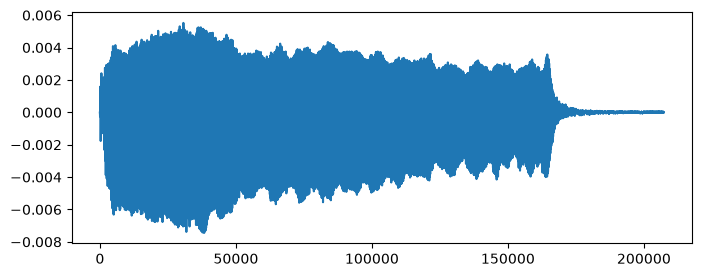

In [90]:
plt.figure(figsize=(8,3))
plt.plot(audio_signal)
plt.show()

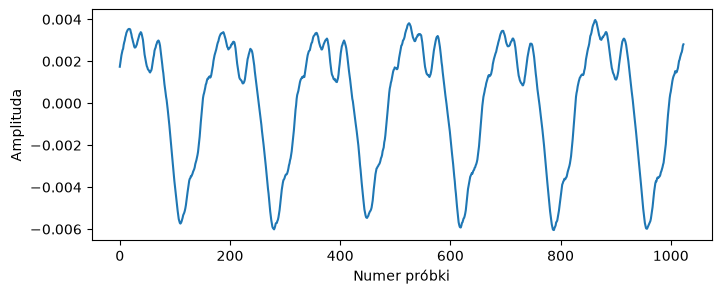

In [91]:
# Wycinek nagrania od 0,2322 sekundy do 0,2544 sekundy
plt.figure(figsize=(8,3))
plt.plot(audio_signal[1024*10:11*1024])
plt.xlabel("Numer próbki")
plt.ylabel("Amplituda")
plt.show()

### Etap 1. Framing + Overlapping
Tniemy plik audio na fragmenty (ramki, które nachodzą na siebie). Musimy zdefiniować parametry:
- długość okna $N$,
- krok przesunięcia $H$,
- liczba ramek $K$.

Dodajemy też padding, czyli wstawiamy N/2 zer na początku sygnały, aby środek pierwszego okna był w chwili $t_0 = 0$.
Dzięki temu lepiej uchwycimy co się dzieje na początku dźwięku (np. okno Hanna ma największą wartość na  środku).

Możemy zrobić padding zerami albo użyć odbicia.

In [98]:
def signal_zero_padding(audio_data, frame_len = 1024, step_len = 512):

    audio_data = np.asarray(audio_data)
    padding_left = frame_len//2
    num_samples = len(audio_data)
    r = num_samples%step_len

    if r != 0:
        add_right = step_len - r
    else:
        add_right = 0

    padding_right = frame_len//2 + add_right

    padded_signal = np.zeros(padding_left + num_samples + padding_right, dtype=audio_data.dtype)
    padded_signal[padding_left: padding_left+num_samples] = audio_data

    return padded_signal


def signal_reflect_padding(audio_data, frame_len = 1024, step_len = 512):

    audio_data = np.asarray(audio_data)
    padding_left = frame_len//2
    num_samples = len(audio_data)
    r = num_samples%step_len

    if r != 0:
            add_right = step_len - r
    else:
        add_right = 0
    
    padding_right = frame_len//2 + add_right

    pad_left = audio_data[1:padding_left+1][::-1]
    pad_right = audio_data[-1-padding_right : -1][::-1]

    padded_signal = np.concatenate([pad_left, audio_data, pad_right])

    return padded_signal
    

In [99]:
padded_signal_reflect = signal_reflect_padding(audio_signal)
len(padded_signal_reflect)

208384

In [100]:
padded_signal = signal_zero_padding(audio_signal)
len(padded_signal)

208384

Chcemy macierz 2D o wymiarach (M,N)
- M - liczba ramek
- N - długość pojedynczej ramki (np. 1024)

m-ty wiersz to ramka sygnału 

In [101]:
def frame_audio(audio_data, frame_len = 1024, step_len = 512, sr = 44100):

    audio_data = np.asarray(audio_data)
    num_of_samples = len(audio_data)
    number_frames = (num_of_samples-frame_len)//step_len + 1

    frames = np.empty((number_frames,frame_len), dtype=audio_data.dtype)

    for i in range(number_frames):
        start = i*step_len
        frames[i] = audio_data[start: frame_len + start]

    return frames

In [84]:
frame_length = 1024
sliced_audio = frame_audio(audio_data=padded_signal_reflect, frame_len=frame_length)
sliced_audio.shape

(406, 1024)

### Etap 2. Okienkowanie
Nakładamy funkcję okna na każdą wycietą ramkę.

- Najbardziej popularna: Hann window

$$w(n) = 0.5 - 0.5*\cos(\frac{2\pi n}{N-1}), \; \; 0 \le n \le N-1$$

- Stosuje się także Hamming window|

In [85]:
def hann_window(frame_len=1024):
    return np.asarray([ (0.5 - 0.5*np.cos(2*np.pi*n/ (frame_len-1))) for n in range(frame_len) ])

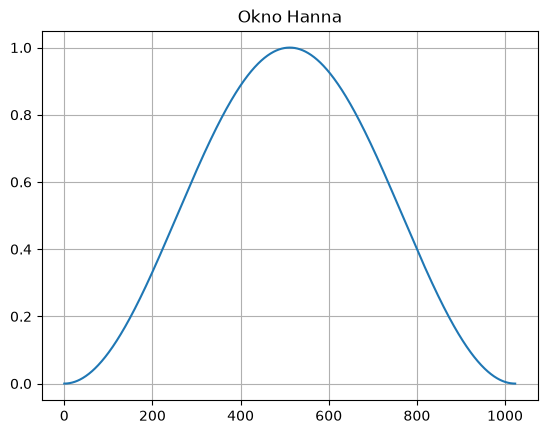

In [103]:
hann_1024 = hann_window(1024)
plt.plot(hann_1024)
plt.grid(True)
plt.title("Okno Hanna")
plt.show()

Teraz należy przemnożyć każdy wycinek sygnału przez okno Hanna.
Operacja ta tłumi sygnał na brzegach ramek i minimalizuje przeciek widma (spectral leakage).

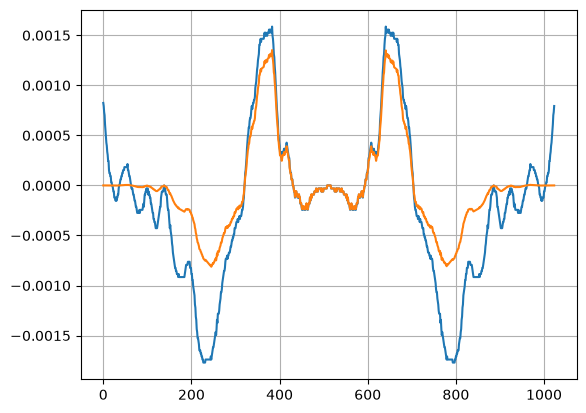

In [74]:
hanned_frames = sliced_audio*hann_1024

plt.plot(sliced_audio[0])
plt.plot(hanned_frames[0])
plt.grid(True)
plt.show()

### Etap 3. STFT

Short-Time Fourier Transform to metoda podziału sygnału audio na małe przedziały i stosowanie DFT (Discrete Fourier Transform) na każdym z przedziałów, czyli badamy częstotliwość na takim małym przedziale.

Korzystamy z FFT (Fast Fourier Transform), czyli szybszego algorytmu wyznaczania DFT (złożoność $N\log(N)$ zamiast $N^2$).
FFT opiera się na algorytmie divide and conquer. Rozbija problem na mniejsze fragmenty

Wynikiem jest dwuwymiarowa macierz częstotliwości i czasu, którą najczęściej przedstawia się wizualnie jako spektrogram\


<img src=https://pythonnumericalmethods.studentorg.berkeley.edu/_images/24.02.02-time_frequency.png width="600" alt="Wizualizacja działania transformaty Fouriera">

Żródło: https://pythonnumericalmethods.studentorg.berkeley.edu/_images/24.02.02-time_frequency.png

$$X_k = \sum_{n=0}^{N-1}{x_n\cdot e^{-i2\pi{kn/N}}} = \sum_{n=0}^{N-1}{x_n[cos(2\pi{kn/N}) -i\cdot sin(2\pi{kn/N})]}$$
- N - liczba próbek
- n - obecna próbka
- k - obecna częstotliwość, $k\in [0,N-1]$
- $x_n$ - wartość sygnału w n-tej próbce
- $X_k$ - Transformata Fouriera z próbki $x_n$

Wyjściowo dla pojedynczej ramki sygnału chcemy wektor długości $N$.

Możemy powyższy wzór zapisać w postaci mnożenia macierzy. W wierszach są kolejne wartości $k$. pojedynczy wiersz zawiera zespolone wartości widma dla danego prążka k.

In [75]:
def DFT(signal):
    signal = np.asarray(signal)
    N = signal.shape[-1]
    #broadcasting
    #wiersze to czas (n), a kolumny to częstotliwość (k)
    k = np.arange(N)
    n = np.arange(N).reshape(N,1)

    expr = np.exp(-2j * np.pi * k * n / N) # symetryczna macierz

    # signal (M,N) 
    return np.dot(signal, expr)

def FFT(signal):
    # Funkcja ma obsługiwać wejście (liczba_ramek x długość ramki)
    # zrobić: wektoryzacja funkcji
    signal = np.asarray(signal)
    N = len(signal)

    if N%2 > 0:
        raise ValueError('Długość sygnału powinna być potęgą 2')

    elif N <= 8:
        return DFT(signal)

    k = np.arange(N//2)
    
    even = FFT(signal[::2])
    odd = FFT(signal[1::2])

    expr = np.exp(-2j * np.pi * k  / N)

    X_first_half = even + expr*odd
    X_second_half = even - expr*odd
    return np.concat([X_first_half,X_second_half])
    

### Testowanie implementacji

In [76]:
# Losowa ramka testowa (128 próbek)
test_frame = np.sin(np.random.randn(128))

my_dft = DFT(test_frame)
numpy_fft = np.fft.fft(test_frame)

# Porównanie
max_error = np.max(np.abs(my_dft - numpy_fft))
print(f"Maksymalny błąd bezwzględny: {max_error:.2e}")

Maksymalny błąd bezwzględny: 4.61e-13


##### Dla sygnału audio (sygnałów rzeczywistych) druga połowa współczynników ($k > N/2$) to lustrzane odbicie pierwszej. 

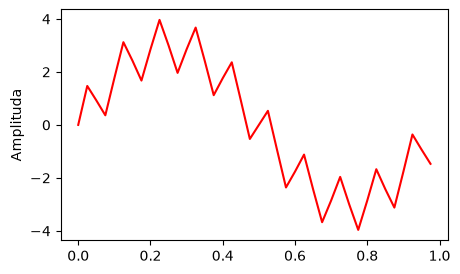

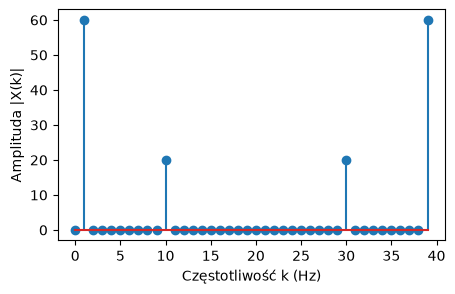

In [22]:
# Gdy częstotliwości to liczby całkowite

# sampling rate
sr = 40
# sampling interval
ts = 1.0/sr
t = np.arange(0,1,ts)

freq = 1
x = 3*np.sin(2*np.pi*freq*t)

freq = 10
x += np.sin(2*np.pi*freq*t)

#freq = 10   
#x += 0.5* np.sin(2*np.pi*freq*t)

plt.figure(figsize = (5, 3))
plt.plot(t, x, 'r')
plt.ylabel('Amplituda')

plt.show()

dft_x = DFT(x)

N = len(dft_x)
n = np.arange(N)
T = N/sr
freq = n/T 


plt.figure(figsize = (5, 3))
plt.stem(freq, abs(dft_x))
plt.xlabel('Częstotliwość k (Hz)')
plt.ylabel('Amplituda |X(k)|')
plt.show()

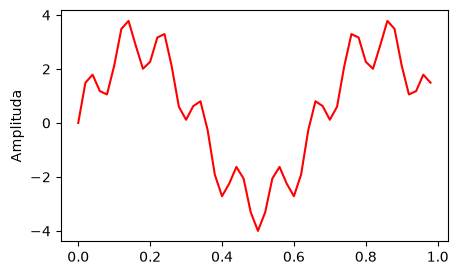

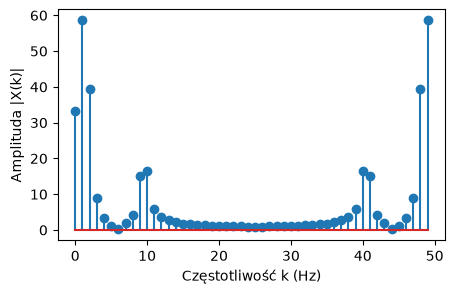

In [69]:
## Przykład przecieku widma

# sampling rate
sr = 50
# sampling interval
ts = 1.0/sr
t = np.arange(0,1,ts)

freq = 1.5
x = 3*np.sin(2*np.pi*freq*t)

freq = 9.5
x += np.sin(2*np.pi*freq*t)

#freq = 10   
#x += 0.5* np.sin(2*np.pi*freq*t)

plt.figure(figsize = (5, 3))
plt.plot(t, x, 'r')
plt.ylabel('Amplituda')

plt.show()

dft_x = DFT(x)

N = len(dft_x)
n = np.arange(N)
T = N/sr
freq = n/T 


plt.figure(figsize = (5, 3))
plt.stem(freq, abs(dft_x))
plt.xlabel('Częstotliwość k (Hz)')
plt.ylabel('Amplituda |X(k)|')
plt.show()

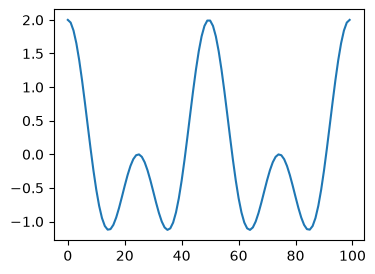

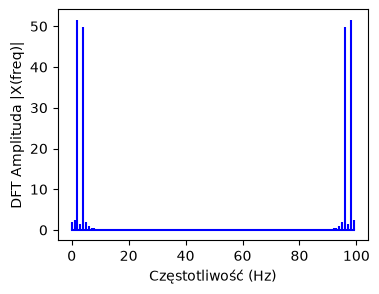

In [36]:
x = np.linspace(0, 1, 100)
a = np.cos(x*8*np.pi)
b = np.cos(x*4*np.pi)
c = 2*np.sin(x*2*np.pi) * 0
out = a + b + c
plt.figure(figsize = (4, 3))
plt.plot(out)
plt.show()


dft_out = DFT(out)
dft_build_in = np.fft.fft(out)

N = len(dft_out)
n = np.arange(N)
T = N/100
freq = n/T 


plt.figure(figsize = (4, 3))
plt.stem(freq, np.abs(dft_out), 'b', \
         markerfmt=" ", basefmt="-b")
plt.xlabel('Częstotliwość (Hz)')
plt.ylabel('DFT Amplituda |X(freq)|')
plt.show()


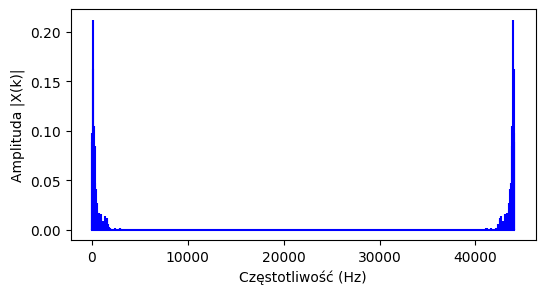

In [61]:
hanned_frame = hanned_frames[0]
frame_after_dft = DFT(hanned_frame)

# Obliczamy częstotliwość
N = len(frame_after_dft)
n = np.arange(N)
T = N/sample_rate
freq = n/T 

plt.figure(figsize = (6, 3))
plt.stem(freq, abs(frame_after_dft), 'b', \
         markerfmt=" ", basefmt="-b")
plt.xlabel('Częstotliwość (Hz)')
plt.ylabel('Amplituda |X(k)|')
plt.show()

In [37]:
# Teraz przeporwadzamy DFT na każdym z przedziale z nałożonym oknem Hanna
#dft_frames = np.array([DFT(frame) for frame in hanned_frames])
fft_frames = np.array([FFT(frame) for frame in hanned_frames])

#### Wyznaczamy periodogram
Tzw. Power Spectrum

####  $P = \frac{|FFT(\mathbf{x}_i)|^2}{N}$

Dzielimy przez N aby unormować energię w każdym oknie oraz aby energia ramki nie zależała sztucznie od długości tej ramki

1024


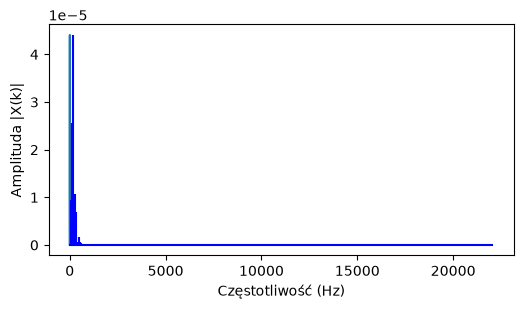

In [38]:
N = len(fft_frames[0])
print(N)
num_bins = N//2 + 1
power_frames = np.abs(fft_frames)**2 / N

linear_spectrogram = power_frames[:, : num_bins]

# Obliczamy częstotliwość

n = np.arange( N//2 + 1)
T = N/sample_rate
freq = n/T

plt.figure(figsize = (6, 3))
plt.plot(linear_spectrogram[0])
plt.stem(freq, linear_spectrogram[0], 'b', \
         markerfmt=" ", basefmt="-b")
plt.xlabel('Częstotliwość (Hz)')
plt.ylabel('Amplituda |X(k)|')
plt.show()

# Badanie wpływu okna Hanna na transformatę Fouriera

Brak nałożenia funkcji okienkowej może doprowadzić do wycieku widma. Sprawdźmy jak wygląda wycinek pliku audio po przepuszczeniu przez DFT, ale bez wcześniejszego nałożenia okna Hanna

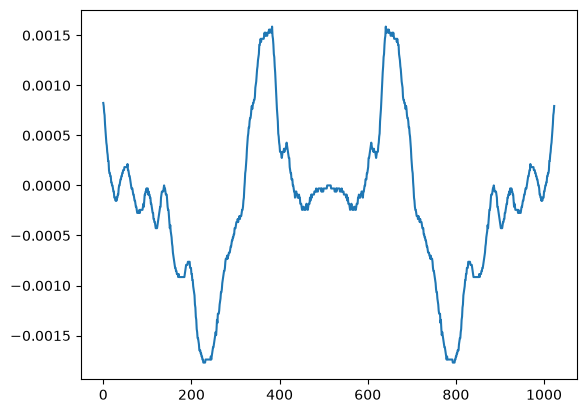

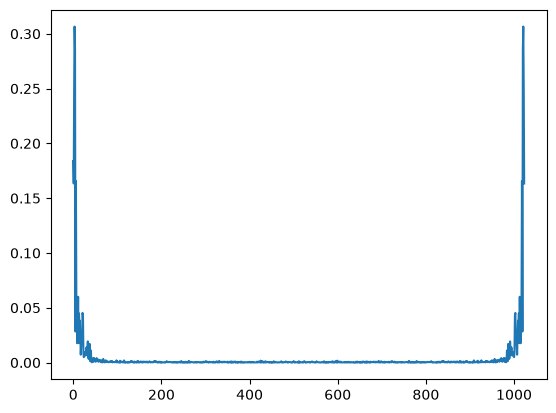

In [39]:
frame_without_hann = sliced_audio[0]
plt.plot(frame_without_hann)
plt.show()

dft_no_hann = np.abs(DFT(frame_without_hann))
plt.plot(dft_no_hann)
plt.show()

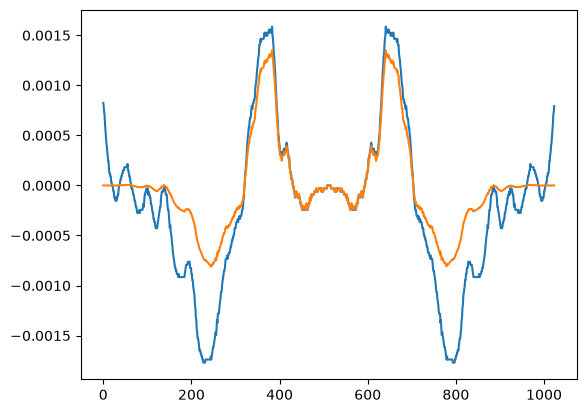

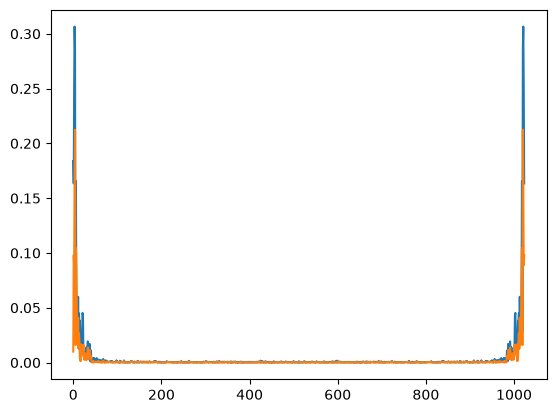

In [43]:
raw = sliced_audio[0]
hanned = hanned_frames[0]

plt.plot(raw)
plt.plot(hanned)
plt.show()

dft_no_hann = np.abs(DFT(raw))
dft_hann = np.abs(DFT(hanned))
plt.plot(dft_no_hann)
plt.plot(dft_hann)
plt.show()

### Mel Filterbank
Nakładanie filtrów trójkątnych
Bank filtrów Melowych to proces agregacji (grupowania) setek wąskich, liniowych prążków DFT w znacznie mniejszą liczbę szerszych pasm.

Fragment posta (https://haythamfayek.com/2016/04/21/speech-processing-for-machine-learning.html )

The final step to computing filter banks is applying triangular filters, typically 40 filters, nfilt = 40 on a Mel-scale to the power spectrum to extract frequency bands.

The Mel-scale aims to mimic the non-linear human ear perception of sound, by being more discriminative at lower frequencies and less discriminative at higher frequencies. We can convert between Hertz (f) and Mel (m) using the following equations:

$$m = 2595 \log_{10} (1 + \frac{f}{700})$$
$$ f = 700 (10^{m/2595} - 1) $$


<img src=https://haythamfayek.com/assets/posts/post1/mel_filters.jpg width="1000" alt="Wizualizacja działania transformaty Fouriera">


Fragment artykułu, który tłumaczy jak stworzyć filterbanki mel http://practicalcryptography.com/miscellaneous/machine-learning/guide-mel-frequency-cepstral-coefficients-mfccs/ 

Musimy ustalić najwyższą i najniższą częstotliwość i zmienić je na mele. Jako górną częstotliwość przyjmujemy 22 050 Hz (połowa wartości próbkowania), jako dolną wartość przyjmujemy 20 lub 40 Hz

Dla M filtrów musimy wygenerować M+2 punktów, pojedynczy filtr trójkątny potrzebuje 3 punktów węzłowych. Pierwszy filtr 0,1,2 drugi 1,2,3 itd.

In [49]:
def freq_to_mel(point):
    return 2595*np.log10(1 + point/700)

def mel_to_freq(point):
    return 700* (10**(point/2595) - 1)

In [50]:
print(freq_to_mel(22050))

3923.337321740179


In [51]:
def create_mel_filterbank(lowest_freq, highest_freq, n_mel_filters = 64, frame_len = 1024, sr = 44100):
    lowest_mel = freq_to_mel(lowest_freq)
    highest_mel = freq_to_mel(highest_freq)

    # Liczba prążków widma DFT
    n_bins = frame_len//2 +1

    mel_grid = np.linspace(lowest_mel, highest_mel, num = n_mel_filters + 2)

    # Konwersja do Hz
    herz_grid = mel_to_freq(mel_grid)

    # Musimy przybliżeć te częstotliwości do najbliższej częstotliwości ramki po zastosowaniu DFT
    nearest_DFT_bin =  np.floor((frame_len * herz_grid/ sr))

    # Inicjalizacja macierzy filtrów (513, liczba filtrów mel)
    # każdy wiersz to pojedynczy filtr Melowy o długości równej liczbie prążków DFT (513) 
    filterbanks = np.zeros((n_mel_filters, n_bins), dtype=np.float32)

    # Wypełnienie macierzy filtrami trójkątnymi
    for m in range(1, n_mel_filters + 1):
        left_point = int(nearest_DFT_bin[m-1])
        center_point = int(nearest_DFT_bin[m])
        right_point = int(nearest_DFT_bin[m+1])
        #print(left_point, center_point, right_point)

        if left_point < center_point:
            for k in range(left_point, center_point):
                #print((k-left_point)/ (center_point - left_point))
                filterbanks[m-1, k] = (k-left_point)/ (center_point - left_point)

        if center_point < right_point:
            for k in range(center_point, right_point):
                #print( (right_point + k)/(right_point - center_point) )
                filterbanks[m-1, k] = (right_point - k)/(right_point - center_point) 

    return filterbanks

Kształt macierzy filtrów: (10, 513)


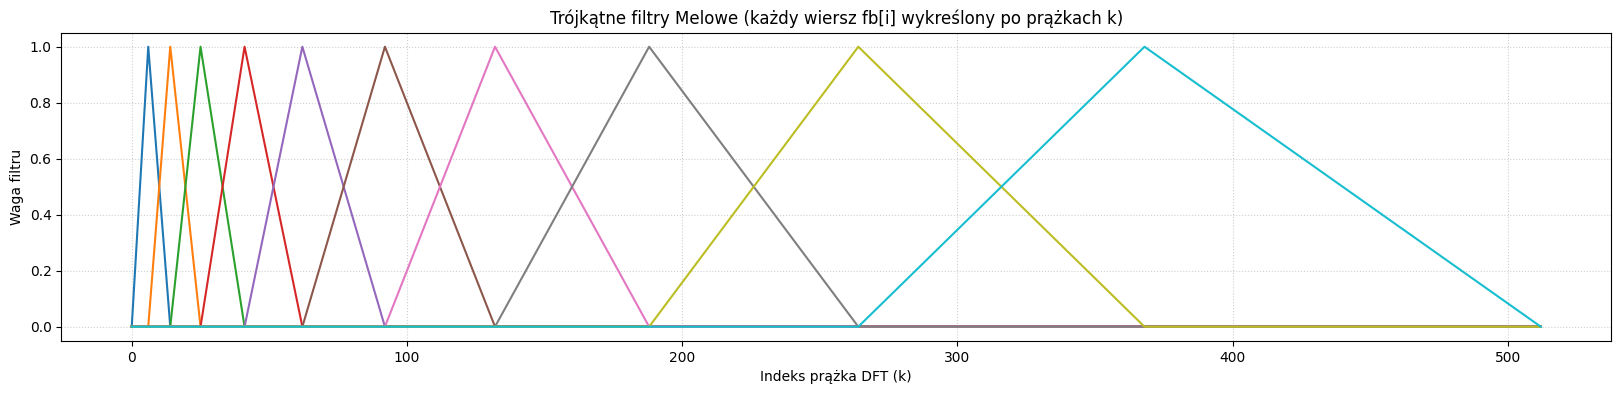

In [52]:
# Utworzenie banku dla zakresu od 0 Hz do częstotliwości Nyquista (22050 Hz)
liczba_filtrow = 10
fb = create_mel_filterbank(
    lowest_freq=0, highest_freq=sample_rate // 2, n_mel_filters=liczba_filtrow)

print(f"Kształt macierzy filtrów: {fb.shape}")

# Wykres filtrów w dziedzinie prążków DFT k
plt.figure(figsize=(20, 4))
for i in range(liczba_filtrow):
    plt.plot(fb[i])
plt.title(
    "Trójkątne filtry Melowe (każdy wiersz fb[i] wykreślony po prążkach k)"
)
plt.xlabel("Indeks prążka DFT (k)")
plt.ylabel("Waga filtru")
plt.grid(True, linestyle=":", alpha=0.6)
plt.show()

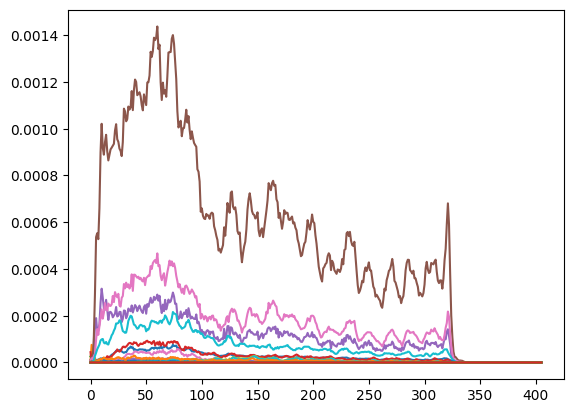

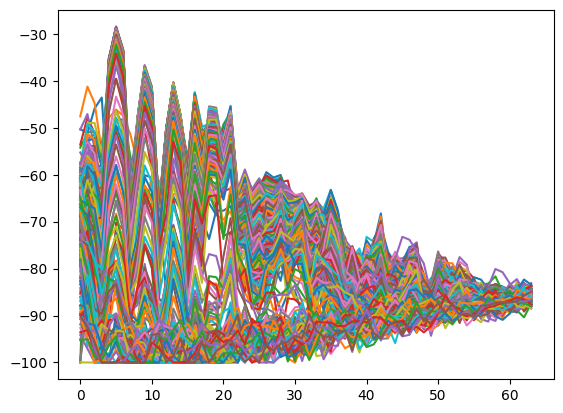

(406, 64)

In [53]:
mel_filterbanks = create_mel_filterbank(lowest_freq= 20,highest_freq= sample_rate//2, n_mel_filters= 64, frame_len=1024, sr = sample_rate)
mel_spectrogram = np.dot(linear_spectrogram, mel_filterbanks.T)
    
#epsilon = np.finfo(np.float64).eps
replace_zero = 1e-10 # standard w bibliotece librosa (-100 decybeli)
mel_spectrogram = np.maximum(mel_spectrogram,replace_zero)

#Różnica między mnożnikiem 10 a 20 wynika bezpośrednio z definicji decybela oraz z tego, czy logarytmujemy wielkość mocy (energię), czy wielkość pola (amplitudę/ciśnienie).
# Konwersja na decybele
mel_spectrogram_dB = 10 * np.log10(mel_spectrogram)

plt.plot(mel_spectrogram)
#plt.xlim((0,50))
plt.show()

plt.plot(mel_spectrogram_dB.T)
#plt.xlim((0,50))
plt.show()
mel_spectrogram_dB.shape

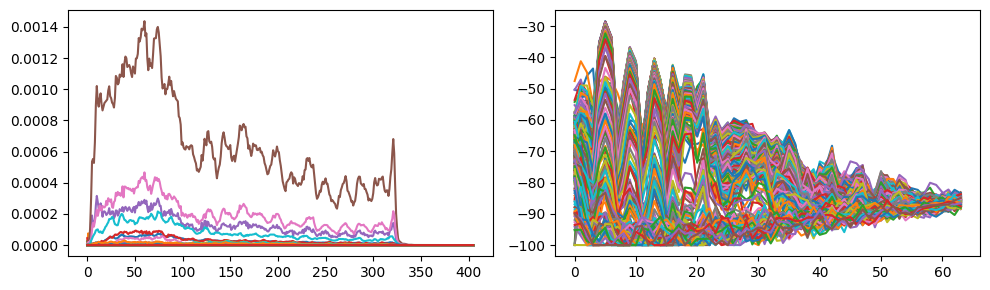

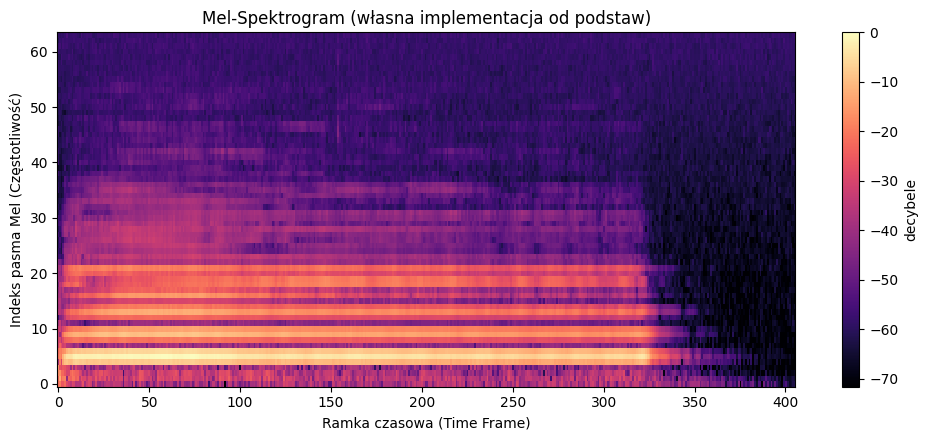

In [54]:
mel_filterbanks = create_mel_filterbank(lowest_freq= 20,highest_freq= sample_rate//2, n_mel_filters= 64, frame_len=1024, sr = sample_rate)
mel_spectrogram = np.dot(linear_spectrogram, mel_filterbanks.T)
    
    # Zabezpieczenie przed log(0)
    # epsilon maszynowy dla float64
#epsilon = np.finfo(np.float64).eps
replace_zero = 1e-10 # standard w bibliotece librosa (-100 decybeli)
mel_spectrogram = np.maximum(mel_spectrogram,replace_zero)


#Różnica między mnożnikiem 10 a 20 wynika bezpośrednio z definicji decybela oraz z tego, czy logarytmujemy wielkość mocy (energię), czy wielkość pola (amplitudę/ciśnienie).
# Konwersja na decybele
mel_spectrogram_dB = 10 * np.log10(mel_spectrogram)

plt.figure(figsize=(10,3))

plt.subplot(1, 2, 1) 
plt.plot(mel_spectrogram)
#plt.xlim((0,50))

plt.subplot(1, 2, 2) 
plt.plot(mel_spectrogram_dB.T)
#plt.xlim((0,50))
plt.tight_layout()

mel_spectrogram_dB.shape

# Normalizacja: najgłośniejszy punkt ma 0 dB, reszta wartości jest ujemna
mel_spectrogram_dB -= np.max(mel_spectrogram_dB)
mel_spectrogram_dB = np.maximum( mel_spectrogram_dB, -80.0 )  # obcięcie do zakresu [-80, 0] dB

plt.figure(figsize=(10, 4.5))

img = plt.imshow(
    mel_spectrogram_dB.T,
    origin="lower",
    aspect="auto",
    cmap="magma", 
    interpolation="nearest",
)

cbar = plt.colorbar(img)
cbar.set_label("decybele")

plt.title("Mel-Spektrogram (własna implementacja od podstaw)")
plt.xlabel("Ramka czasowa (Time Frame)")
plt.ylabel("Indeks pasma Mel (Częstotliwość)")
plt.tight_layout()
plt.show()

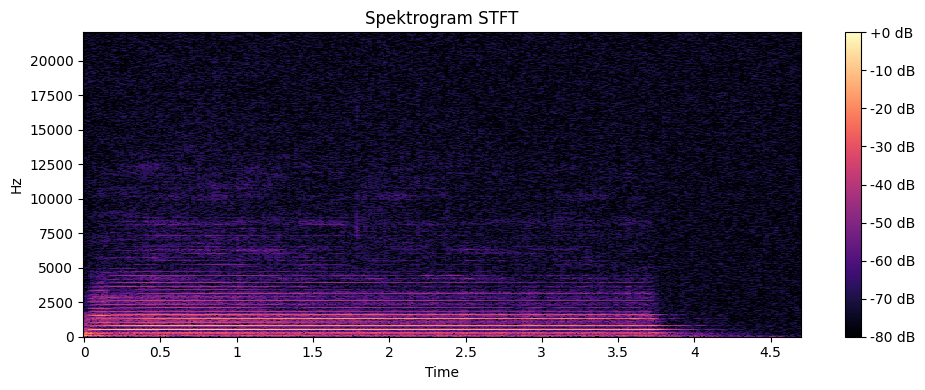

In [13]:
import librosa
import librosa.display
sr= 44100
# 1. Obliczenie STFT (zwraca liczby zespolone)
lib_stft = librosa.stft(audio_signal)

# 2. Moduł z liczb zespolonych i konwersja amplitudy na decybele (dB)
stft_db = librosa.amplitude_to_db(np.abs(lib_stft), ref=np.max)

# 3. Rysowanie spektrogramu
fig, ax = plt.subplots(figsize=(10, 4))

# Przekazujemy sr (częstotliwość próbkowania), aby osie miały realne jednostki
img = librosa.display.specshow(
    stft_db, 
    sr=sr,               # np. 22050 lub 44100
    x_axis="time", 
    y_axis="hz",         # lub "log" dla skali logarytmicznej częstotliwości
    ax=ax
)

# 4. Dodanie paska skali w decybelach (Colorbar)
fig.colorbar(img, ax=ax, format="%+2.0f dB")
ax.set_title("Spektrogram STFT")
plt.tight_layout()
plt.show()

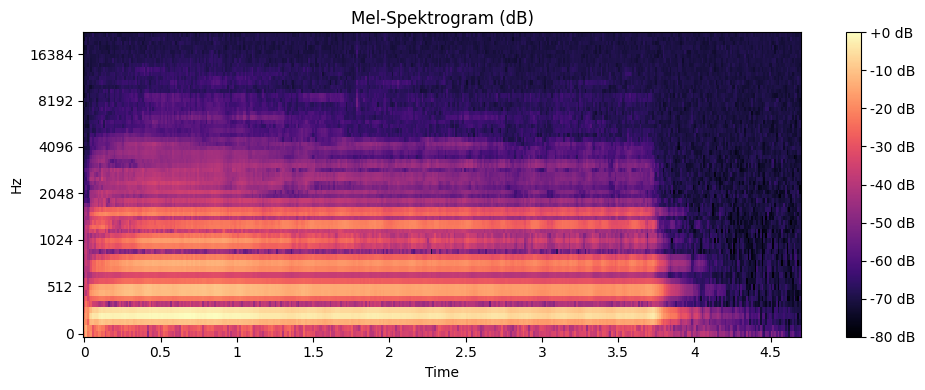

In [14]:

# 1. Wczytanie pliku audio (lub użycie istniejącego audio_signal i sr)
# audio_signal, sr = librosa.load("sciezka/do/pliku.wav", sr=None)

# 2. Obliczenie Mel-Spektrogramu
# Domyślnie funkcja zwraca moc sygnału (power = |STFT|^2)
hop_length = 512
n_fft = 1024
n_mels = 64  # Liczba filtrów na skali Mel

mel_spec = librosa.feature.melspectrogram(
    y=audio_signal,
    sr=sr,
    n_fft=n_fft,
    hop_length=hop_length,
    n_mels=n_mels,
    power=2.0
)

# 3. Konwersja mocy na decybele (dB)
# Ponieważ mel_spec to moc (energia), używamy power_to_db zamiast amplitude_to_db
mel_spec_db = librosa.power_to_db(mel_spec, ref=np.max)

# 4. Rysowanie Mel-Spektrogramu
fig, ax = plt.subplots(figsize=(10, 4))

img = librosa.display.specshow(
    mel_spec_db,
    x_axis="time",
    y_axis="mel",         # Ustawienie osi Y na nieliniową skalę Mel
    sr=sr,
    hop_length=hop_length,
    fmax=sr // 2,         # Maksymalna częstotliwość (częstotliwość Nyquista)
    ax=ax
)

fig.colorbar(img, ax=ax, format="%+2.0f dB")
ax.set_title("Mel-Spektrogram (dB)")
plt.tight_layout()
plt.show()

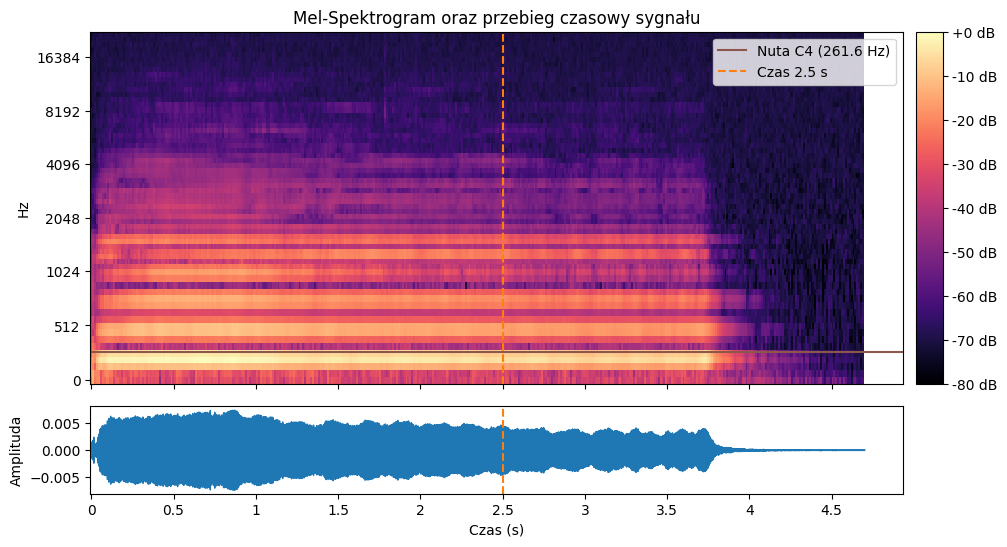

In [15]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np

# 1. Parametry Mel-Spektrogramu
hop_length = 512
n_fft = 1024
n_mels = 64

# Obliczenie spektrogramu i konwersja na dB
mel_spec = librosa.feature.melspectrogram(
    y=audio_signal,
    sr=sr,
    n_fft=n_fft,
    hop_length=hop_length,
    n_mels=n_mels,
    power=2.0
)
mel_spec_db = librosa.power_to_db(mel_spec, ref=np.max)

# Siatka: 2 wiersze, 2 kolumny (druga kolumna zarezerwowana na pasek skali)
fig = plt.figure(figsize=(11, 6))
gs = fig.add_gridspec(2, 2, height_ratios=[4, 1], width_ratios=[30, 1], hspace=0.1, wspace=0.03)

ax0 = fig.add_subplot(gs[0, 0])
cax = fig.add_subplot(gs[0, 1])
ax1 = fig.add_subplot(gs[1, 0], sharex=ax0)

# Spektrogram
img = librosa.display.specshow(
    mel_spec_db,
    x_axis="time",
    y_axis="mel",
    sr=sr,
    hop_length=hop_length,
    fmax=sr // 2,
    ax=ax0
)

note_hz = librosa.note_to_hz("C4")
ax0.axhline(note_hz, label=f"Nuta C4 ({note_hz:.1f} Hz)", color="C5")
ax0.axvline(2.5, label="Czas 2.5 s", color="C1", linestyle="--")
ax0.set_title("Mel-Spektrogram oraz przebieg czasowy sygnału")
ax0.legend(loc="upper right")
ax0.label_outer()

# Colorbar w dedykowanej komórce siatki
fig.colorbar(img, cax=cax, format="%+2.0f dB")

# Fala dźwiękowa
librosa.display.waveshow(y=audio_signal, sr=sr, ax=ax1)
ax1.axvline(2.5, color="C1", linestyle="--")
ax1.set_ylabel("Amplituda")
ax1.set_xlabel("Czas (s)")

plt.show()

# Scalenie wszystkich etapów do jednej funkcji

In [66]:
def create_mel_spectrogram_from_audio(  audio_signal,
                                        frame_length = 1024,
                                        step_length = 512,
                                        sampling_rate = 44100,
                                        padding_type = 'reflect',
                                        window_type = 'hann',
                                        lowest_freq = 20,
                                        highest_freq = 22050,
                                        n_mel_banks = 64,
                                        db= True
                                        ):
    
    if padding_type == 'reflect':
        padded_signal = signal_reflect_padding(audio_data=audio_signal,
                                           frame_len=frame_length,
                                           step_len=step_length)
    elif padding_type == 'zero':
        padded_signal = signal_zero_padding(audio_data=audio_signal,
                                               frame_len=frame_length,
                                               step_len=step_length)
    elif padding_type == None:
        padded_signal = audio_signal

    sliced_audio = frame_audio( padded_signal,
                                frame_len= frame_length,
                                step_len= step_length,
                                sr = sampling_rate)

    if window_type == 'hann':
        window_function = hann_window(frame_len = frame_length)
    elif window_type == 'hamming':
        pass
    elif window_type == None:
        window_function = sliced_audio


    windowed_frames = sliced_audio*window_function

    dft_frames = np.array([FFT(frame) for frame in windowed_frames])

    num_bins = frame_length//2 + 1
    power_frames = np.abs(dft_frames)**2 / frame_length

    linear_spectrogram = power_frames[:, : num_bins]

    mel_filterbanks = create_mel_filterbank(lowest_freq= lowest_freq,
                                            highest_freq= highest_freq,
                                            n_mel_filters= n_mel_banks,
                                            frame_len=frame_length,
                                            sr = sampling_rate)
    
    mel_spectrogram = np.dot(linear_spectrogram, mel_filterbanks.T)
        
    replace_zero = 1e-10 # standard w bibliotece librosa (-100 decybeli)
    mel_spectrogram = np.maximum(mel_spectrogram,replace_zero)

    if db == True:
        mel_spectrogram = 10 * np.log10(mel_spectrogram)
    
    # Normalizacja: najgłośniejszy punkt ma 0 dB, reszta wartości jest ujemna
    mel_spectrogram -= np.max(mel_spectrogram)
    mel_spectrogram = np.maximum( mel_spectrogram, -80.0 )  # obcięcie do zakresu [-80, 0] dB

    return mel_spectrogram.T.astype(np.float32)
    

In [67]:
mel_spect = create_mel_spectrogram_from_audio(audio_signal)


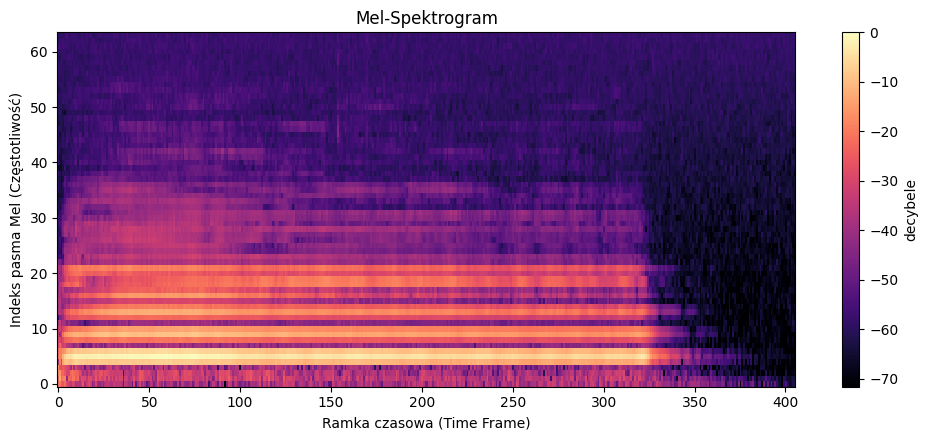

In [68]:
def plot_spectrogram(mel_spectrogram, db = True):

    plt.figure(figsize=(10, 4.5))

    img = plt.imshow(
        mel_spectrogram,
        origin="lower",
        aspect="auto",
        cmap="magma", 
        interpolation="nearest",
    )

    cbar = plt.colorbar(img)
    cbar.set_label("decybele")

    plt.title("Mel-Spektrogram")
    plt.xlabel("Ramka czasowa (Time Frame)")
    plt.ylabel("Indeks pasma Mel (Częstotliwość)")
    plt.tight_layout()
    plt.show()

plot_spectrogram(mel_spectrogram= mel_spect, db=True)

In [79]:
def save_spectrograms_to_file(dataset_name = 'TinySOL',
                              base_dir = '.',
                              frame_length = 1024,
                              step_length = 512,
                              sampling_rate = 44100,
                              padding_type = 'reflect',
                              window_type = 'hann',
                              lowest_freq = 20,
                              highest_freq = 22050,
                              n_mel_banks = 64,
                              db= True
                              ):

    base_path = Path(base_dir)
    data_dir = base_path/"data"/dataset_name

    tag = f"sr{sampling_rate}_fl{frame_length}_sl{step_length}_mels{n_mel_banks}_{window_type}"
    output_dir = base_path/"data"/"spectrograms"/tag/dataset_name
    output_dir.mkdir(parents = True, exist_ok = True)

    metadata = []

    # Pobieramy wszystkie pliki audio
    audio_files = list(data_dir.rglob("*.wav"))
    print(f"Znaleziono {len(audio_files)} plików audio w {data_dir}")

    for index, file_path in enumerate(audio_files):

        audio_data, file_sr = sf.read(file_path, dtype="float32")

        if audio_data.ndim > 1:
            audio_data = np.mean(audio_data, axis=1)

        if file_sr != sampling_rate:

            raise ValueError(
                f"Niezgodny SR w pliku {file_path.name}: {file_sr} != {sampling_rate}"
            )

        relative_to_data_structure = file_path.relative_to(data_dir)
        path_to_save_npy = output_dir/ relative_to_data_structure.with_suffix(".npy")
        path_to_save_npy.parent.mkdir(parents=True, exist_ok = True)

        if not path_to_save_npy.exists():
            mel_spectr = create_mel_spectrogram_from_audio(
                audio_signal=audio_data,
                frame_length=frame_length,
                step_length=step_length,
                sampling_rate=sampling_rate,
                padding_type=padding_type,
                window_type=window_type,
                lowest_freq=lowest_freq,
                highest_freq=highest_freq,
                n_mel_banks=n_mel_banks,
                db=db
            )

            # Zapis
            np.save(path_to_save_npy, mel_spect)

        label = file_path.parent.name

        metadata.append(
            {"sample_id": f"{dataset_name}_{index:05d}",
            "file_name": file_path.name,
            "feature_path": str(path_to_save_npy.relative_to(base_path)),
            "instrument": label,
            "dataset": dataset_name}
        )

        if (index+1) % 20 == 0 or (index) == len(audio_files):
            print(f"Utworzono: {index + 1}/{len(audio_files)} plików")
    
    df_metadata = pd.DataFrame(metadata)
    path_csv = base_path/ "data" / "spectrograms" / tag / f"{dataset_name}_metadata.csv"
    df_metadata.to_csv(path_csv, index = False)
    print(f"Metadane zapisano do: {path_csv}")
    
    # Wczytaj zbiór danych
    
    # Wczytaj plik audio
    # Sprawdź metadane, sampling rate, zapisz nazwę
    # Sprawdź czy sampling rate zgadza się z ustalonym, jeśli nie to resampling

    # Konwersja stereo na mono

    # Zrób spektrogram z ustalonymi parametrami

    # Stwórz nowy folder (chyba że istnieje i nie jest pusty) oznaczając odpowiednie parametry
    # Zapisz spektrogram w formacie .npy do danego folderu

In [81]:
save_spectrograms_to_file(dataset_name="TinySOL_chosen", base_dir='.')

Znaleziono 770 plików audio w data\TinySOL_chosen
Utworzono: 20/770 plików
Utworzono: 40/770 plików
Utworzono: 60/770 plików
Utworzono: 80/770 plików
Utworzono: 100/770 plików
Utworzono: 120/770 plików
Utworzono: 140/770 plików
Utworzono: 160/770 plików
Utworzono: 180/770 plików
Utworzono: 200/770 plików
Utworzono: 220/770 plików
Utworzono: 240/770 plików
Utworzono: 260/770 plików
Utworzono: 280/770 plików
Utworzono: 300/770 plików
Utworzono: 320/770 plików
Utworzono: 340/770 plików
Utworzono: 360/770 plików
Utworzono: 380/770 plików
Utworzono: 400/770 plików
Utworzono: 420/770 plików
Utworzono: 440/770 plików
Utworzono: 460/770 plików
Utworzono: 480/770 plików
Utworzono: 500/770 plików
Utworzono: 520/770 plików
Utworzono: 540/770 plików
Utworzono: 560/770 plików
Utworzono: 580/770 plików
Utworzono: 600/770 plików
Utworzono: 620/770 plików
Utworzono: 640/770 plików
Utworzono: 660/770 plików
Utworzono: 680/770 plików
Utworzono: 700/770 plików
Utworzono: 720/770 plików
Utworzono: 740/770

## Funkcja, która zapisuje pliki ze zbioru slakh w postaci spektrogramów w formacie .npy

In [ ]:
def generate_spectrograms_from_dataset(
        dataset_dir,
        output_dir,
        mel_spectrogram_function,
        sample_rate = 44100,
        file_duration = 4.0,
        overwrite = False
):
    """Przetwarza drzewo plików .wav i .flac na spektrogramy .npy, zachowując strukturę katalogów"""

    
    load_from_path = Path(dataset_dir)
    save_to_path = Path(output_dir)
    
    minimal_num_of_samples = int(file_duration*sample_rate)
    supported_filetype = {'.wav', '.flac'}

    # Przeszukuhjemy wszystkie podkatalogi, aby znaleźć pliki audio
    all_audio_files = [audio_file for audio_file in load_from_path.rglob('*')
                       if audio_file.suffix.lower() in supported_filetype]

    print(f'Znaleziono {len(all_audio_files)} plików audio.')

    # Dodać progress bar

    

